Saving images.jfif to images (1).jfif


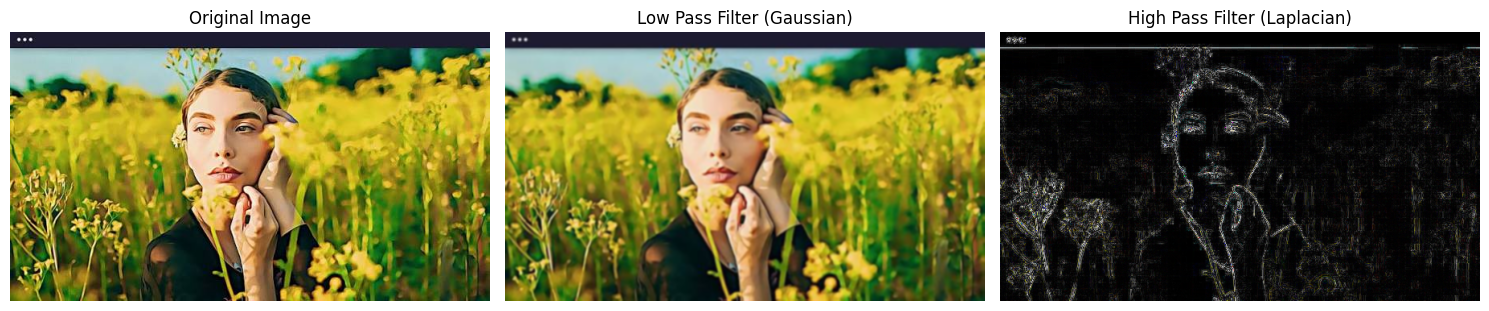

In [19]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

uploaded = files.upload()

# Read the input imag
image = cv2.imread(next(iter(uploaded)))

# Convert BGR to RGB
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Apply Low Pass Filter (Gaussian Blur)
low_pass = cv2.GaussianBlur(image, (5, 5), 0)

# Apply High Pass Filter (Laplacian)
laplacian = cv2.Laplacian(image, cv2.CV_64F)
high_pass = np.uint8(np.absolute(laplacian))

# Display original and filtered images
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(low_pass)
plt.title("Low Pass Filter (Gaussian)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(high_pass)
plt.title("High Pass Filter (Laplacian)")
plt.axis("off")

plt.tight_layout()
plt.show()



In [15]:
def arithmetic_encoding(text):
    frequency = {}
    for char in text:
        frequency[char] = frequency.get(char, 0) + 1

    total = len(text)
    low_range = 0.0
    ranges = {}

    for char, freq in sorted(frequency.items()):
        high_range = low_range + freq / total
        ranges[char] = (low_range, high_range)
        low_range = high_range

    low = 0.0
    high = 1.0

    for char in text:
        range_width = high - low

        char_low, char_high = ranges[char]

        high = low + range_width * char_high
        low = low + range_width * char_low

    encoded_value = (low + high) / 2
    return encoded_value, ranges

text = input("enter the text:")

encoded_value, ranges = arithmetic_encoding(text)

print("Original Text:", text)

print("\nCharacter Probability Ranges:")
for char, (low, high) in ranges.items():
    print(char, ":", low, "-", high)

print("\nArithmetic Encoded Value:", encoded_value)

enter the text:abacca
Original Text: abacca

Character Probability Ranges:
a : 0.0 - 0.5
b : 0.5 - 0.6666666666666666
c : 0.6666666666666666 - 1.0

Arithmetic Encoded Value: 0.2881944444444444
